# 1. Exploring the skin lesion dataset

[HAM10000](https://doi.org/10.7910/DVN/DBW86T) ("Human Against Machine with
10000 training images") is 10,015 dermatoscopic images across seven
diagnostic categories, released for academic machine learning use. This
notebook looks at what the data actually contains before any modelling,
and at one thing that makes part of it unusually trustworthy: **2,259 of
those images come from a University of Queensland-affiliated skin cancer
practice (Cliff Rosendahl's), ethics-approved, and 100% confirmed by
histopathology** -- a biopsy result, not a clinical impression. That
subset is what this project actually trains and evaluates on.

**Why restrict to it rather than use all 10,015 images?** Two honest
reasons, not one. It is the identifiably Australian slice of the dataset,
which matters for this portfolio. But it is also the *highest-confidence
ground truth* in HAM10000 -- the rest relies partly on follow-up exams,
diagnostic consensus among clinicians, or confocal microscopy, methods
that are reasonable but not as certain as a pathology report. Training on
the slice with the most reliable labels is a defensible choice on its own
merits, independent of geography.

**A disclaimer that matters more here than in most portfolio projects:**
this is a machine learning exercise, not a diagnostic device. It has not
been clinically validated. Nothing in this notebook should inform a real
decision about a real lesion -- see a clinician for that.

In [1]:
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the repository layout is recognisable.

    Lets the notebook run from the repo root, from notebooks/, or from a
    Jupyter server started somewhere else entirely.
    """
    for candidate in (start, *start.parents):
        if (candidate / "config").is_dir() and (candidate / "src" / "skinlesion").is_dir():
            return candidate
    raise RuntimeError(f"could not locate the repository root from {start}")


REPO = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO / "src"))

CONFIG = REPO / "config" / "smoke.yaml"   # swap for config/default.yaml for the full 40-species... 10,015-image run
print(f"repository root: {REPO}")

repository root: /Users/cherylt/projects/skin-lesion-id


In [2]:
from skinlesion.config import load_config
from skinlesion.data.metadata import read_metadata, drop_sparse_classes

config = load_config(CONFIG)
records = read_metadata(
    REPO / config.paths.metadata_file,
    allowed_classes=config.data.classes,
    source_filter=config.data.source_filter,
)
records, dropped = drop_sparse_classes(records, config.data.min_images_per_class)

print(f"{len(records):,} images")
print(f"{len({r.dx for r in records})} diagnoses kept, dropped for too few images: {list(dropped)}")
print(f"{len({r.lesion_id for r in records}):,} distinct lesions")
print(f"all Australian (Rosendahl/Queensland)?  {all(r.is_australian for r in records)}")

2,226 images
5 diagnoses kept, dropped for too few images: ['df', 'vasc']
1,534 distinct lesions
all Australian (Rosendahl/Queensland)?  True


## The images-per-lesion problem

The direct analogue of the photos-per-observation problem in the
nudibranch project. HAM10000 sometimes has more than one dermatoscopic
image of the same lesion -- a follow-up shot, a slightly different crop.
If those land on both sides of a split, the model can partly memorise the
lesion rather than learn to generalise, and the resulting accuracy is
inflated.

Every image from one lesion therefore lands in exactly one split,
enforced in [`splits.py`](../src/skinlesion/data/splits.py) and checkable
at runtime via `assert_no_leakage`, which the training script calls
before a single epoch runs.

In [3]:
import pandas as pd

frame = pd.DataFrame([
    {"dx": r.dx, "lesion_id": r.lesion_id, "dx_type": r.dx_type,
     "age": r.age, "sex": r.sex, "localization": r.localization}
    for r in records
])

per_lesion = frame.groupby("lesion_id").size()

print(f"mean images per lesion:   {per_lesion.mean():.2f}")
print(f"median:                   {per_lesion.median():.0f}")
print(f"maximum:                  {per_lesion.max()}")
print(f"lesions with >1 image:    {(per_lesion > 1).mean():.1%}")

mean images per lesion:   1.45
median:                   1
maximum:                  5
lesions with >1 image:    36.6%


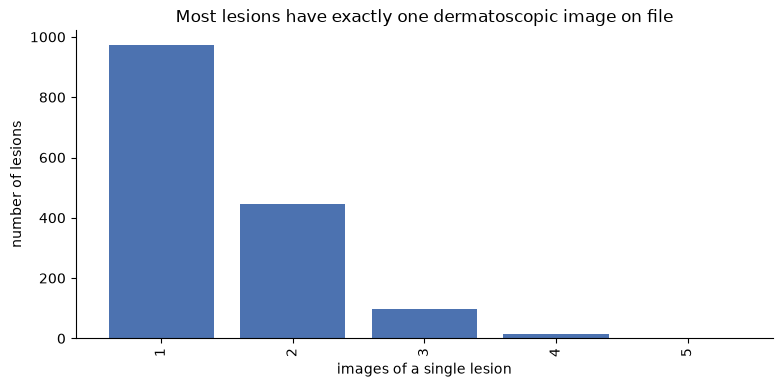

In [4]:
ax = per_lesion.value_counts().sort_index().plot(
    kind="bar", figsize=(9, 4), color="#4C72B0", width=0.8
)
ax.set_xlabel("images of a single lesion")
ax.set_ylabel("number of lesions")
ax.set_title("Most lesions have exactly one dermatoscopic image on file")
ax.spines[["top", "right"]].set_visible(False)

## Class balance

Long tailed, the same shape of problem as the nudibranch dataset:
melanocytic nevi (ordinary moles) are photographed and biopsied far more
often than rarer diagnoses, because most of what a skin cancer clinic
biopsies turns out benign. Plain accuracy would reward a model that
simply learns to call everything a nevus, which is why evaluation reports
macro-F1 and a melanoma-specific recall figure alongside accuracy, and
training weights the loss by inverse class frequency.

   803  nv     Melanocytic nevus
   490  bkl    Benign keratosis
   342  mel    Melanoma
   296  bcc    Basal cell carcinoma
   295  akiec  Actinic keratosis / intraepithelial carcinoma

imbalance ratio (largest:smallest): 2.7x


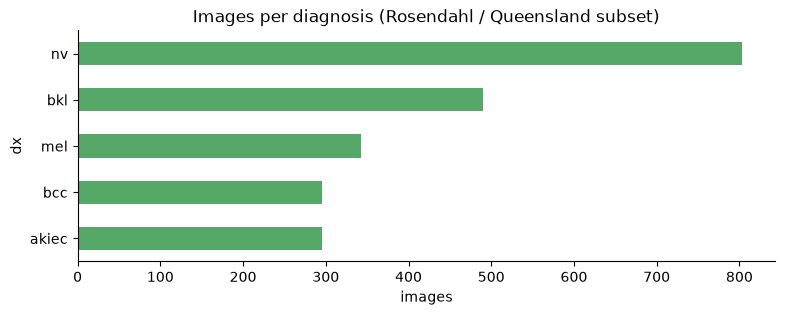

In [5]:
from skinlesion.data.metadata import DIAGNOSIS_NAMES

counts = frame["dx"].value_counts()

ax = counts.plot(kind="barh", figsize=(9, max(3, len(counts) * 0.5)), color="#55A868")
ax.set_xlabel("images")
ax.set_title("Images per diagnosis (Rosendahl / Queensland subset)")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)

for dx, count in counts.items():
    print(f"  {count:>4}  {dx:<6} {DIAGNOSIS_NAMES[dx]}")
print(f"\nimbalance ratio (largest:smallest): {counts.max() / counts.min():.1f}x")

## Ground truth confidence

Worth stating explicitly, because it is the actual reason this project
uses this subset rather than the full 10,015 images. HAM10000's `dx_type`
column records how each label was established.

In [6]:
print("dx_type, this subset (Rosendahl):")
print(frame["dx_type"].value_counts().to_string())

print()
print("For comparison, across the full HAM10000 dataset, only ~53% of")
print("labels are histopathology-confirmed; the rest rely on follow-up")
print("examination, clinical consensus among multiple dermatologists, or")
print("confocal microscopy. Every label used in this project is the")
print("strongest of those four: a biopsy result.")

dx_type, this subset (Rosendahl):
dx_type
histo    2226

For comparison, across the full HAM10000 dataset, only ~53% of
labels are histopathology-confirmed; the rest rely on follow-up
examination, clinical consensus among multiple dermatologists, or
confocal microscopy. Every label used in this project is the
strongest of those four: a biopsy result.


## Who the data represents

Worth a look before training anything: a model only performs well on
inputs that resemble what it saw during training.

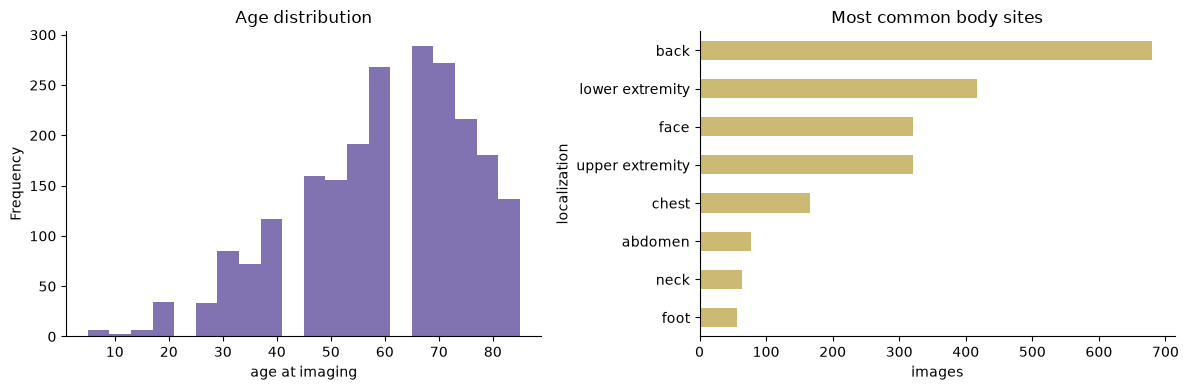

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

frame["age"].dropna().plot(kind="hist", bins=20, ax=axes[0], color="#8172B2")
axes[0].set_xlabel("age at imaging")
axes[0].set_title("Age distribution")
axes[0].spines[["top", "right"]].set_visible(False)

frame["localization"].value_counts().head(8).plot(kind="barh", ax=axes[1], color="#CCB974")
axes[1].invert_yaxis()
axes[1].set_xlabel("images")
axes[1].set_title("Most common body sites")
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()

## What the images look like

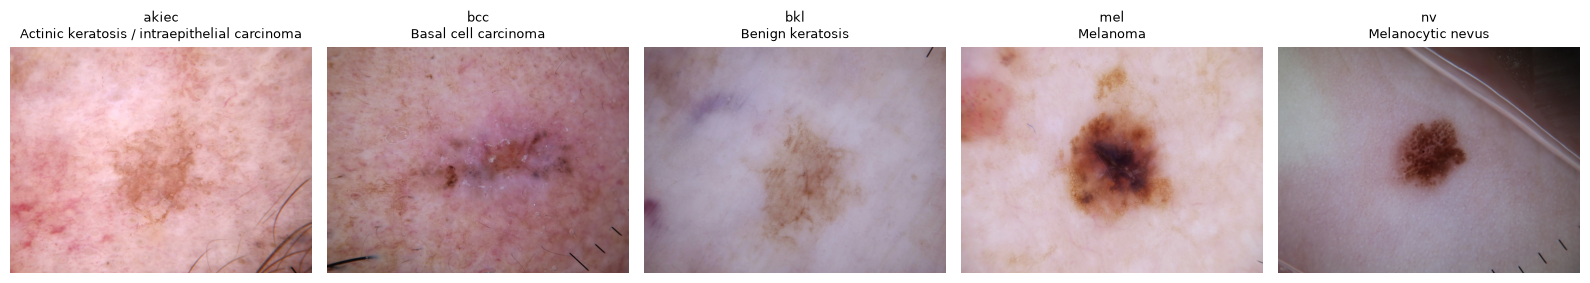

In [8]:
from PIL import Image

images_dir = REPO / config.paths.images_dir
per_dx_example = {r.dx: r for r in records}   # last one wins, fine for a sample grid

fig, axes = plt.subplots(1, len(per_dx_example), figsize=(3.2 * len(per_dx_example), 3.6))
for ax, (dx, record) in zip(axes, sorted(per_dx_example.items())):
    path = images_dir / record.filename
    if path.is_file():
        ax.imshow(Image.open(path))
    ax.set_title(f"{dx}\n{DIAGNOSIS_NAMES[dx]}", fontsize=9)
    ax.axis("off")
fig.tight_layout()

## Conclusions carried into the next notebook

1. Images cluster within lesions, so splits must be grouped by lesion.
   This is enforced in `skinlesion.data.splits` and asserted by
   `assert_no_leakage`, exactly as in the nudibranch project.
2. The diagnosis distribution is long tailed, so evaluation uses macro-F1
   and top-k rather than plain accuracy, and training weights the loss.
3. Missing a malignant lesion matters more than missing a benign one, so
   evaluation reports a dedicated malignant-recall figure, not just
   per-class scores that treat every misclassification the same.
4. Every label here is histopathology-confirmed, which is not true of
   HAM10000 as a whole -- worth remembering when comparing results
   against a model trained on the full dataset.